# Router Pattern (라우터 패턴)

**라우터 패턴(Router Pattern)** 은 라우팅 단계에서 입력을 분류하고, 전문 에이전트로 라우팅하며,
결과를 통합하여 결합된 응답을 생성하는 멀티 에이전트 아키텍처입니다.

이 패턴은 조직의 지식이 서로 다른 **수직 영역(verticals)** 에 분산되어 있을 때 특히 효과적입니다.
각 영역은 고유한 도구와 프롬프트를 가진 전문 에이전트가 필요합니다.

이 튜토리얼에서는 GitHub, Notion, Slack 세 가지 지식 소스를 통합하는 라우터를 구축합니다.

**참고**: [LangChain 공식 문서 - Router Knowledge Base](https://docs.langchain.com/oss/python/langchain/multi-agent/router-knowledge-base)

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from langchain.chat_models import init_chat_model

# 메인 모델과 라우터용 경량 모델
model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)
router_llm = init_chat_model(  # 라우터는 경량 모델 사용 가능
    os.environ["OPENAI_MODEL_SMALL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)

## 1. 상태 정의

라우터의 상태를 정의합니다.

In [3]:
from typing import TypedDict, Annotated, Literal
import operator

# 각 에이전트 노드에 전달되는 입력 (Send로 전달되는 상태)
class AgentInput(TypedDict):
    """각 하위 에이전트 노드의 입력"""
    query: str

# 분류 결과
class Classification(TypedDict):
    """라우팅 결정: 어떤 에이전트를 어떤 쿼리로 호출할지"""
    source: Literal["github", "notion", "slack"]
    query: str

# 에이전트 출력
class AgentOutput(TypedDict):
    """각 하위 에이전트의 출력"""
    source: str
    result: str

# 라우터 상태 (results는 reducer로 병렬 결과 수집)
class RouterState(TypedDict):
    """라우터의 전체 상태"""
    query: str
    classifications: list[Classification]
    results: Annotated[list[AgentOutput], operator.add]
    final_answer: str

## 2. 도구 정의

각 지식 소스별로 도구를 정의합니다.

In [4]:
from langchain.tools import tool

# GitHub 도구
@tool
def search_code(query: str, repo: str = "main") -> str:
    """GitHub 저장소에서 코드를 검색합니다."""
    return f"코드 검색 결과 '{query}' in {repo}: src/auth.py의 인증 미들웨어"

@tool
def search_issues(query: str) -> str:
    """GitHub 이슈와 풀 리퀘스트를 검색합니다."""
    return f"'{query}'와 일치하는 이슈 3개 발견: #142 (API 인증 문서), #89 (OAuth 플로우), #203 (토큰 갱신)"

@tool
def search_prs(query: str) -> str:
    """구현 세부사항을 위해 풀 리퀘스트를 검색합니다."""
    return f"PR #156에서 JWT 인증 추가, PR #178에서 OAuth 스코프 업데이트"

# Notion 도구
@tool
def search_notion(query: str) -> str:
    """Notion 워크스페이스에서 문서를 검색합니다."""
    return f"문서 발견: 'API 인증 가이드' - OAuth2 플로우, API 키, JWT 토큰 다룸"

@tool
def get_page(page_id: str) -> str:
    """특정 Notion 페이지를 ID로 가져옵니다."""
    return f"페이지 내용: 단계별 인증 설정 지침"

# Slack 도구
@tool
def search_slack(query: str) -> str:
    """Slack 메시지와 스레드를 검색합니다."""
    return f"#engineering 채널에서 토론 발견: 'API 인증에는 Bearer 토큰 사용, 갱신 플로우는 문서 참조'"

@tool
def get_thread(thread_id: str) -> str:
    """특정 Slack 스레드를 가져옵니다."""
    return f"스레드에서 API 키 로테이션 모범 사례 논의"

## 3. 전문 에이전트 생성

각 지식 소스별로 전문 에이전트를 생성합니다.

In [5]:
from langchain.agents import create_agent

# GitHub 에이전트
github_agent = create_agent(
    model,
    tools=[search_code, search_issues, search_prs],
    system_prompt=(
        "당신은 GitHub 전문가입니다. "
        "코드, API 참조, 구현 세부사항에 대한 질문에 답변하기 위해 "
        "저장소, 이슈, 풀 리퀘스트를 검색하세요."
    ),
)

# Notion 에이전트
notion_agent = create_agent(
    model,
    tools=[search_notion, get_page],
    system_prompt=(
        "당신은 Notion 전문가입니다. "
        "내부 프로세스, 정책, 팀 문서에 대한 질문에 답변하기 위해 "
        "조직의 Notion 워크스페이스를 검색하세요."
    ),
)

# Slack 에이전트
slack_agent = create_agent(
    model,
    tools=[search_slack, get_thread],
    system_prompt=(
        "당신은 Slack 전문가입니다. "
        "관련 스레드와 토론을 검색하여 팀원들이 공유한 지식과 해결책을 찾아 답변하세요."
    ),
)

## 4. 쿼리 분류

사용자 쿼리를 분석하여 어떤 에이전트를 호출할지 결정합니다.

In [6]:
from pydantic import BaseModel, Field

# 구조화된 출력 스키마
class ClassificationResult(BaseModel):
    """쿼리 분류 결과"""
    classifications: list[Classification] = Field(
        description="호출할 에이전트와 타겟팅된 하위 질문 목록"
    )

def classify_query(state: RouterState) -> dict:
    """쿼리를 분류하고 어떤 에이전트를 호출할지 결정합니다."""
    structured_llm = router_llm.with_structured_output(ClassificationResult)
    
    system_prompt = """이 쿼리를 분석하고 어떤 지식 베이스를 참조할지 결정하세요.
각 관련 소스에 대해 해당 소스에 최적화된 타겟팅된 하위 질문을 생성하세요.

사용 가능한 소스:
- github: 코드, API 참조, 구현 세부사항, 이슈, 풀 리퀘스트
- notion: 내부 문서, 프로세스, 정책, 팀 위키
- slack: 팀 토론, 비공식 지식 공유, 최근 대화

쿼리와 관련된 소스만 반환하세요."""
    
    result = structured_llm.invoke([
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": state["query"]}
    ])
    
    return {"classifications": result.classifications}

## 5. 라우팅 및 에이전트 노드 (병렬 실행)

route_to_agents는 Send 목록을 반환하여 선택된 에이전트들을 병렬로 실행합니다.
각 에이전트 노드는 AgentInput을 받아 결과만 반환합니다.

In [7]:
from langchain_core.messages import HumanMessage
from langgraph.types import Send

# 병렬 분기 생성
def route_to_agents(state: RouterState) -> list:
    """
    분류 결과(classifications)에 따라
    각 전문 에이전트 노드로 Send 객체를 반환합니다.

    반환값:
        list[Send]
        → LangGraph가 해당 노드들을 병렬로 실행합니다.

    예:
        state["classifications"] = [
            {"source": "github", "query": "..."},
            {"source": "notion", "query": "..."}
        ]

        반환:
            [
                Send("github", {"query": "..."}),
                Send("notion", {"query": "..."})
            ]
    """

    return [
        # Send(노드 이름, 해당 노드에 전달할 상태)
        Send(c["source"], {"query": c["query"]})
        for c in state["classifications"]
    ]


# ------------------------------------------------------------
# GitHub 에이전트 호출 노드
# ------------------------------------------------------------
# 이 함수는 Graph의 "github" 노드에 해당합니다.
# AgentInput 형태의 state를 입력받아 GitHub 전문 에이전트를 실행합니다.
def query_github(state: AgentInput) -> dict:
    """
    GitHub 에이전트를 호출하여
    코드, 이슈, PR 관련 정보를 조회합니다.

    입력:
        state: {"query": "..."}  (AgentInput)

    출력:
        {"results": [{"source": "github", "result": "..."}]}
        → reducer(operator.add)에 의해 RouterState.results에 누적됨
    """

    # GitHub 전문 Agent 실행
    result = github_agent.invoke({
        "messages": [
            {"role": "user", "content": state["query"]}
        ]
    })

    last = result["messages"][-1]
    text = last.text   # Responses API: content는 블록 리스트 → .text로 텍스트만 추출

    # 결과를 RouterState.results에 추가할 형식으로 반환
    return {
        "results": [
            {
                "source": "github",  # 출처 명시
                "result": text       # 에이전트 응답 텍스트
            }
        ]
    }


# ------------------------------------------------------------
# Notion 에이전트 호출 노드
# ------------------------------------------------------------
def query_notion(state: AgentInput) -> dict:
    """
    Notion 에이전트를 호출하여
    내부 문서, 정책, 위키 정보를 조회합니다.
    """

    result = notion_agent.invoke({
        "messages": [
            {"role": "user", "content": state["query"]}
        ]
    })

    last = result["messages"][-1]
    text = last.text   # Responses API: content는 블록 리스트 → .text로 텍스트만 추출

    return {
        "results": [
            {
                "source": "notion",
                "result": text
            }
        ]
    }


# ------------------------------------------------------------
# Slack 에이전트 호출 노드
# ------------------------------------------------------------
def query_slack(state: AgentInput) -> dict:
    """
    Slack 에이전트를 호출하여
    팀 대화 및 스레드에서 관련 정보를 검색합니다.
    """

    result = slack_agent.invoke({
        "messages": [
            {"role": "user", "content": state["query"]}
        ]
    })

    last = result["messages"][-1]
    text = last.text   # Responses API: content는 블록 리스트 → .text로 텍스트만 추출

    return {
        "results": [
            {
                "source": "slack",
                "result": text
            }
        ]
    }

## 6. 결과 통합 (synthesize)

병렬로 수집된 results를 reducer가 합쳤으므로, 이를 바탕으로 최종 답변을 생성합니다.

In [8]:
def synthesize_answer(state: RouterState) -> dict:
    """모든 에이전트 결과를 통합하여 최종 답변을 생성합니다."""
    query = state["query"]
    results = state.get("results") or []

    if not results:
        return {"final_answer": "어떤 지식 소스에서도 결과를 찾지 못했습니다."}

    # 결과 요약
    results_summary = "\n\n".join(
        f"[{r['source']}] {r['result']}"
        for r in results
    )
    
    # 최종 답변 생성
    prompt = f"""다음은 여러 지식 소스에서 수집한 정보입니다.

원본 질문: {query}

검색 결과:
{results_summary}

위 정보를 바탕으로 원본 질문에 대한 포괄적이고 정확한 답변을 생성하세요.
각 소스의 정보를 통합하여 일관된 답변을 제공하세요."""
    
    response = model.invoke([HumanMessage(content=prompt)])
    answer = response.text
    
    return {"final_answer": answer}

## 7. 그래프 구성 (병렬 라우팅)

classify 후 route_to_agents가 반환하는 Send 목록에 따라 github/notion/slack 노드가 병렬 실행되고,
각 결과가 reducer(operator.add)로 results에 수집된 뒤 synthesize로 넘어갑니다.

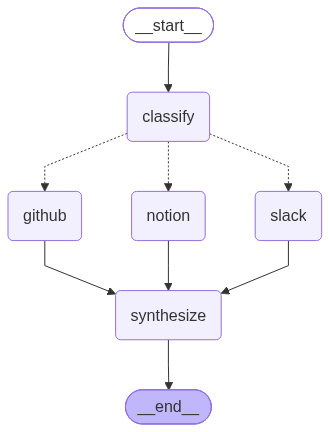

In [9]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(RouterState)

workflow.add_node("classify", classify_query)
workflow.add_node("github", query_github)
workflow.add_node("notion", query_notion)
workflow.add_node("slack", query_slack)
workflow.add_node("synthesize", synthesize_answer)

workflow.add_edge(START, "classify")
workflow.add_conditional_edges("classify", route_to_agents, ["github", "notion", "slack"])
workflow.add_edge("github", "synthesize")
workflow.add_edge("notion", "synthesize")
workflow.add_edge("slack", "synthesize")
workflow.add_edge("synthesize", END)

router_graph = workflow.compile()
router_graph

## 8. 라우터 실행

다양한 쿼리로 라우터를 테스트합니다.

In [10]:
# 쿼리 1: API 인증
query1 = "API 요청을 어떻게 인증하나요?"

print("=" * 80)
print(f"쿼리: {query1}")
print("=" * 80)

result1 = router_graph.invoke({
    "query": query1,
    "classifications": [],
    "results": [],
    "final_answer": ""
})

print("\n분류 결과:")
for cls in result1["classifications"]:
    print(f"  - {cls['source']}: {cls['query']}")

print("\n에이전트 결과:")
for r in result1["results"]:
    print(f"  [{r['source']}]: {r['result'][:100]}...")

print("\n최종 답변:")
print(result1["final_answer"])

쿼리: API 요청을 어떻게 인증하나요?

분류 결과:
  - github: 이 프로젝트의 API 요청 인증 방식은 무엇인가요? 지원하는 인증 방법(예: API 키, Bearer 토큰, OAuth), 필요한 헤더나 요청 형식, 관련 구현 및 API 문서를 찾아주세요.
  - notion: 내부 문서에서 API 요청 인증 방법과 자격 증명 발급·관리 절차, 필요한 헤더 또는 권한 설정을 확인해 주세요.

에이전트 결과:
  [github]: 현재 검색 결과만으로는 이 프로젝트가 실제로 지원하는 인증 방식이나 요청 형식을 확정할 수 없습니다. 검색 도구는 `src/auth.py`를 인증 미들웨어로 지목했지만, 파일 내용...
  [notion]: 내부 문서에서 **「API 인증 가이드」**를 찾았습니다. 검색 결과 요약에는 **OAuth 2.0 플로우, API 키, JWT 토큰**을 다룬다고 되어 있습니다.

다만 페이지 ...

최종 답변:
현재 확인된 정보만으로는 이 API의 정확한 인증 방법을 확정할 수 없습니다. 내부 문서 요약에는 **OAuth 2.0, API 키, JWT 토큰**이 언급되어 있지만, 실제로 어떤 방식을 지원하는지와 요청에 자격 증명을 어떻게 전달해야 하는지는 확인되지 않았습니다. 저장소 검색 결과도 인증 관련 파일과 이슈·PR만 가리킬 뿐, 구현이나 요청 예제를 보여 주지 않습니다.

따라서 `Authorization: Bearer …` 또는 특정 API 키 헤더를 사용하라고 단정하기는 어렵습니다. 정확한 안내를 위해서는 `src/auth.py`의 내용, 관련 이슈·PR 본문 또는 「API 인증 가이드」 전체 내용을 확인해야 합니다.


## 9. 스트리밍 실행

각 단계를 스트리밍으로 확인합니다.

In [11]:
query2 = "OAuth 인증 플로우는 어떻게 작동하나요?"

print("=" * 80)
print(f"쿼리: {query2}")
print("=" * 80)

for step in router_graph.stream({
    "query": query2,
    "classifications": [],
    "results": [],
    "final_answer": ""
}, stream_mode="values"):
    if "classifications" in step and step["classifications"]:
        print("\n[분류 단계]")
        for cls in step["classifications"]:
            print(f"  → {cls['source']}: {cls['query']}")
    
    if "results" in step and step["results"]:
        print("\n[결과 수집 단계]")
        for r in step["results"]:
            print(f"  [{r['source']}]: {r['result'][:80]}...")
    
    if "final_answer" in step and step["final_answer"]:
        print("\n[최종 답변]")
        print(step["final_answer"])

쿼리: OAuth 인증 플로우는 어떻게 작동하나요?

[분류 단계]
  → notion: 내부 문서나 팀 위키에서 OAuth 인증 플로우의 단계, 지원하는 OAuth 방식, 관련 정책과 설정을 설명하는 자료를 찾아주세요.
  → github: 코드와 문서에서 OAuth 인증 플로우의 구현을 찾아주세요. 인증 단계, 사용 중인 grant type, 콜백 처리와 토큰 발급·갱신 방식을 확인해주세요.

[분류 단계]
  → notion: 내부 문서나 팀 위키에서 OAuth 인증 플로우의 단계, 지원하는 OAuth 방식, 관련 정책과 설정을 설명하는 자료를 찾아주세요.
  → github: 코드와 문서에서 OAuth 인증 플로우의 구현을 찾아주세요. 인증 단계, 사용 중인 grant type, 콜백 처리와 토큰 발급·갱신 방식을 확인해주세요.

[결과 수집 단계]
  [notion]: 관련 문서로 **「API 인증 가이드」**를 찾았습니다. 검색 결과에 따르면 OAuth2 플로우와 API 키, JWT 토큰을 다루며, 페이지 내...
  [github]: 검색 결과, OAuth 인증 구현은 `src/auth.py`의 인증 미들웨어에서 찾을 수 있습니다. 검색어 `grant_type=authoriz...

[분류 단계]
  → notion: 내부 문서나 팀 위키에서 OAuth 인증 플로우의 단계, 지원하는 OAuth 방식, 관련 정책과 설정을 설명하는 자료를 찾아주세요.
  → github: 코드와 문서에서 OAuth 인증 플로우의 구현을 찾아주세요. 인증 단계, 사용 중인 grant type, 콜백 처리와 토큰 발급·갱신 방식을 확인해주세요.

[결과 수집 단계]
  [notion]: 관련 문서로 **「API 인증 가이드」**를 찾았습니다. 검색 결과에 따르면 OAuth2 플로우와 API 키, JWT 토큰을 다루며, 페이지 내...
  [github]: 검색 결과, OAuth 인증 구현은 `src/auth.py`의 인증 미들웨어에서 찾을 수 있습니다. 검색어 `gran

## 10. 실전 예제: 다양한 쿼리 패턴

In [ ]:
queries = [
    "코드 리뷰 프로세스는 어떻게 되나요?",
    "새로운 기능 개발 가이드라인은?",
    "배포 절차는 어떻게 되나요?"
]

for query in queries:
    print("\n" + "=" * 80)
    print(f"쿼리: {query}")
    print("=" * 80)
    
    result = router_graph.invoke({
        "query": query,
        "classifications": [],
        "results": [],
        "final_answer": ""
    })
    
    print(f"\n관련 소스: {[cls['source'] for cls in result['classifications']]}")
    print(f"\n답변: {result['final_answer'][:200]}...")


쿼리: 코드 리뷰 프로세스는 어떻게 되나요?

관련 소스: ['notion', 'slack']

답변: 현재 확인 가능한 Notion 문서와 Slack 검색 결과에서는 코드 리뷰 절차, 리뷰어 지정 방식, 승인 요건, 병합 기준을 찾지 못했습니다. 검색된 내용은 API 인증 관련 정보로, 코드 리뷰 질문과는 무관합니다.

따라서 내부 코드 리뷰 정책을 확인된 사실처럼 안내하기는 어렵습니다. 개발 가이드, 저장소별 `CONTRIBUTING` 문서, PR 템플릿...

쿼리: 새로운 기능 개발 가이드라인은?


## 주요 포인트 정리

1. **라우터 패턴**: 쿼리 분류 → 전문 에이전트로 라우팅 → 결과 통합
2. **병렬 처리**: 여러 에이전트를 동시에 호출하여 효율성 향상
3. **전문 에이전트**: 각 지식 소스별로 최적화된 에이전트
4. **결과 통합**: 여러 소스의 정보를 하나의 일관된 답변으로 통합
5. **확장성**: 새로운 지식 소스를 쉽게 추가 가능

**다음 단계**: 
- [340_Skills_Pattern.py](340_Skills_Pattern.py)에서 스킬 기반 패턴 학습
- [310_Subagents_Pattern.py](310_Subagents_Pattern.py)에서 하위 에이전트 패턴 비교